In [ ]:
import pandas as pd
import numpy as np
import re

In [ ]:
import pandas as pd
import numpy as np
import re


# ============================================================
# 1. Load data
# ============================================================

df = pd.read_csv("Artworks.csv")


# ============================================================
# 2. Helper: expand shortened year ranges
#
# Examples:
# 1976-77 -> 1977
# 1998-02 -> 2002
# 2006-14 -> 2014
# ============================================================

def expand_short_year(start_year, end_text):

    start_year = int(start_year)
    end_text = str(end_text)

    # Full 4-digit year
    if len(end_text) == 4:
        return int(end_text)

    digits = len(end_text)
    end_number = int(end_text)

    base = (start_year // (10 ** digits)) * (10 ** digits)
    end_year = base + end_number

    # Example:
    # 1998-02 -> 2002
    if end_year < start_year:
        end_year += 10 ** digits

    return end_year


# ============================================================
# 3. Main parser
# ============================================================

def parse_moma_date(value, circa_pad=2):

    # --------------------------------------------------------
    # Missing
    # --------------------------------------------------------

    if pd.isna(value):
        return np.nan, np.nan, np.nan, "missing"

    raw = str(value).strip()

    s = raw.lower().strip()

    # Normalize dash characters
    s = (
        s.replace("−", "-")
         .replace("–", "-")
         .replace("—", "-")
    )

    # Normalize spaces
    s = re.sub(r"\s+", " ", s)

    # Remove simple outer parentheses
    #
    # (1966) -> 1966
    # (c. 1950) -> c. 1950
    #
    while s.startswith("(") and s.endswith(")"):
        s = s[1:-1].strip()


    # ========================================================
    # 4. Unknown / unusable
    # ========================================================

    unknown_pattern = (
        r"(?:"
        r"n\.?\s*d\.?|"
        r"unknown|"
        r"unkown|"
        r"tbd|"
        r"tbc|"
        r"undated|"
        r"no date|"
        r"date unknown|"
        r"not dated|"
        r"various|"
        r"\?"
        r")"
    )

    if re.fullmatch(unknown_pattern, s):
        return np.nan, np.nan, np.nan, "unknown"


    # ========================================================
    # 5. BC / BCE
    #
    # We decided to EXCLUDE these from analysis.
    #
    # Example:
    # c. 3000 B.C.
    # ========================================================

    if re.search(
        r"\b(?:b\.?\s*c\.?\s*e?\.?|bce)\b",
        s,
        flags=re.IGNORECASE
    ):
        return np.nan, np.nan, np.nan, "bc_excluded"


    # ========================================================
    # 6. Open-ended dates
    #
    # Examples:
    # Before 1900
    # After 1938
    # 1899 or before
    # 1931 or after
    # Probably before 1898
    #
    # Do not invent an exact year.
    # ========================================================

    open_ended_patterns = [

        r"^(?:probably\s+)?before\s+\d{4}\??\.?$",

        r"^(?:probably\s+)?after\s+\d{4}\??\.?$",

        r"^\(?\s*(?:probably\s+)?before\s+\d{4}\s*\)?$",

        r"^\(?\s*(?:probably\s+)?after\s+\d{4}\s*\)?$",

        r"^\d{4}\s+(?:or\s+)?before\??\.?$",

        r"^\d{4}\s+(?:or\s+)?after\??\.?$",
    ]

    if any(
        re.fullmatch(pattern, s)
        for pattern in open_ended_patterns
    ):
        return (
            np.nan,
            np.nan,
            np.nan,
            "open_ended_excluded"
        )


    # ========================================================
    # IMPORTANT PRINCIPLE FROM HERE:
    #
    # Parse the PRIMARY date expression at the BEGINNING
    # of the string whenever possible.
    #
    # This prevents:
    #
    # 1944 (after a drawing of 1924-25)
    #
    # from incorrectly becoming 1924.5.
    # ========================================================


    # ========================================================
    # 7. Circa range AT START
    #
    # c. 1938-60
    # ca. 1940-1945
    # circa 1950-1953
    #
    # Since the source already supplies a range,
    # do not add ±2 again.
    # ========================================================

    m = re.match(
        r"^(?:c\.?|ca\.?|circa)\s*"
        r"(\d{4})\s*-\s*(\d{1,4})",
        s
    )

    if m:

        lower = int(m.group(1))

        upper = expand_short_year(
            lower,
            m.group(2)
        )

        return (
            lower,
            upper,
            (lower + upper) / 2,
            "circa_range"
        )


    # ========================================================
    # 8. Circa single year AT START
    #
    # c. 1950 -> 1948-1952
    # ========================================================

    m = re.match(
        r"^(?:c\.?|ca\.?|circa)\s*(\d{4})\b",
        s
    )

    if m:

        y = int(m.group(1))

        lower = y - circa_pad
        upper = y + circa_pad

        return (
            lower,
            upper,
            float(y),
            "circa"
        )


    # ========================================================
    # 9. Alternative exact years
    #
    # 1936 or 1937
    #
    # Treat as an interval instead of arbitrarily taking 1936.
    # ========================================================

    m = re.match(
        r"^(\d{4})\s+or\s+(\d{4})\b",
        s
    )

    if m:

        y1 = int(m.group(1))
        y2 = int(m.group(2))

        lower = min(y1, y2)
        upper = max(y1, y2)

        return (
            lower,
            upper,
            (lower + upper) / 2,
            "alternative_years"
        )


    # ========================================================
    # 10. Year range AT START
    #
    # 1955-1958
    # 1976-77
    #
    # Also:
    # 1947-49, published 1949
    #
    # Because the PRIMARY date appears first.
    # ========================================================

    m = re.match(
        r"^(\d{4})\s*-\s*(\d{1,4})\b",
        s
    )

    if m:

        lower = int(m.group(1))

        upper = expand_short_year(
            lower,
            m.group(2)
        )

        return (
            lower,
            upper,
            (lower + upper) / 2,
            "range"
        )


    # ========================================================
    # 11. Decades
    #
    # 1930s
    # early 1930s
    # mid 1930s
    # late 1930s
    # ========================================================

    m = re.match(
        r"^(early|mid(?:dle)?|late)?\s*"
        r"(\d{4})s\b",
        s
    )

    if m:

        position = (m.group(1) or "").lower()

        base = int(m.group(2))

        if position == "early":

            lower = base
            upper = base + 3

        elif position.startswith("mid"):

            lower = base + 4
            upper = base + 6

        elif position == "late":

            lower = base + 7
            upper = base + 9

        else:

            lower = base
            upper = base + 9

        return (
            lower,
            upper,
            (lower + upper) / 2,
            "decade_" + (
                position if position else "full"
            )
        )


    # ========================================================
    # 12. Century
    #
    # 19th century
    # early 19th century
    # mid 19th century
    # late 19th century
    #
    # 19th century = 1800-1899
    # ========================================================

    m = re.match(
        r"^(early|mid(?:dle)?|late)?\s*"
        r"(\d{1,2})(?:st|nd|rd|th)"
        r"\s+century"
        r"(?:\s+c\.?e\.?)?",
        s
    )

    if m:

        position = (m.group(1) or "").lower()

        century = int(m.group(2))

        start = (century - 1) * 100
        end = century * 100 - 1

        if position == "early":

            lower = start
            upper = start + 33

        elif position.startswith("mid"):

            lower = start + 34
            upper = start + 66

        elif position == "late":

            lower = start + 67
            upper = end

        else:

            lower = start
            upper = end

        return (
            lower,
            upper,
            (lower + upper) / 2,
            "century_" + (
                position if position else "full"
            )
        )


    # ========================================================
    # 13. Century range
    #
    # 4th-6th century C.E.
    # ========================================================

    m = re.match(
        r"^(\d{1,2})(?:st|nd|rd|th)"
        r"\s*-\s*"
        r"(\d{1,2})(?:st|nd|rd|th)"
        r"\s+century"
        r"(?:\s+c\.?e\.?)?",
        s
    )

    if m:

        c1 = int(m.group(1))
        c2 = int(m.group(2))

        lower = (c1 - 1) * 100
        upper = c2 * 100 - 1

        return (
            lower,
            upper,
            (lower + upper) / 2,
            "century_range"
        )


    # ========================================================
    # 14. Exact primary year AT START
    #
    # This is intentionally BEFORE searching for ranges later
    # in the string.
    #
    # Examples:
    #
    # 1937 (assembled after 1939)
    #      -> 1937
    #
    # 1944 (after a drawing of 1924-25)
    #      -> 1944
    #
    # 1969, published 1970
    #      -> 1969
    #
    # ========================================================

    m = re.match(
        r"^(\d{4})(?!\d)",
        s
    )

    if m:

        y = int(m.group(1))

        return (
            y,
            y,
            float(y),
            "primary_exact_year"
        )


    # ========================================================
    # 15. Month / day / exact textual dates
    #
    # March 12, 1854
    # June 9, 1962
    # April 1956
    #
    # We only care about the year.
    # ========================================================

    month_pattern = (
        r"^(?:"
        r"january|february|march|april|may|june|"
        r"july|august|september|october|november|december"
        r")"
    )

    if re.match(month_pattern, s):

        m = re.search(
            r"(?<!\d)(\d{4})(?!\d)",
            s
        )

        if m:

            y = int(m.group(1))

            return (
                y,
                y,
                float(y),
                "calendar_date"
            )


    # ========================================================
    # 16. Publication-only / printing-only records
    #
    # Examples:
    #
    # published 1968
    # printed 1973
    #
    # These are NOT safely interpretable as creation year.
    # ========================================================

    if re.match(
        r"^(published|printed|publication|edition)\b",
        s
    ):

        return (
            np.nan,
            np.nan,
            np.nan,
            "publication_only_excluded"
        )


    # ========================================================
    # 17. Conservative fallback
    #
    # If there is a clear four-digit year elsewhere,
    # retain it, BUT label it separately.
    #
    # This allows us to inspect these records later.
    # ========================================================

    m = re.search(
        r"(?<!\d)(\d{4})(?!\d)",
        s
    )

    if m:

        y = int(m.group(1))

        return (
            y,
            y,
            float(y),
            "fallback_embedded_year"
        )


    # ========================================================
    # 18. Cannot parse
    # ========================================================

    return (
        np.nan,
        np.nan,
        np.nan,
        "unparsed"
    )


# ============================================================
# 19. Apply parser
# ============================================================

parsed = (
    df["Date"]
    .apply(parse_moma_date)
    .apply(pd.Series)
)

parsed.columns = [
    "year_lower",
    "year_upper",
    "year_mid",
    "date_type"
]

df_clean = pd.concat(
    [df, parsed],
    axis=1
)


# ============================================================
# 20. Analysis dataset
#
# Rules:
#
# ✓ Must have a valid parsed date
# ✓ No lower bound of 1800
# ✓ Exclude BC
# ✓ Exclude dates beyond 2026
#
# For intervals, require the WHOLE interval <= 2026.
# ============================================================

df_analysis = df_clean[
    df_clean["year_mid"].notna()
    &
    (df_clean["year_upper"] <= 2026)
    &
    ~df_clean["date_type"].isin([
        "bc_excluded"
    ])
].copy()


# ============================================================
# 21. Basic check
# ============================================================

print("Original rows:")
print(len(df))

print("\nUsable rows:")
print(len(df_analysis))

print("\nDate type counts:")
print(
    df_clean["date_type"]
    .value_counts()
)


# ============================================================
# 22. Specifically inspect fallback cases
#
# These are the most useful records to manually audit.
# ============================================================

fallback = df_clean[
    df_clean["date_type"]
    == "fallback_embedded_year"
]

print("\nFallback embedded years:")
print(len(fallback))

print(
    fallback[
        [
            "Date",
            "year_lower",
            "year_upper",
            "year_mid"
        ]
    ]
    .head(100)
    .to_string(index=False)
)


# ============================================================
# 23. Check excluded open-ended records
# ============================================================

print("\nOpen-ended excluded:")
print(
    df_clean[
        df_clean["date_type"]
        == "open_ended_excluded"
    ]["Date"]
    .head(50)
    .to_string(index=False)
)


# ============================================================
# 24. Check future dates
# ============================================================

future_dates = df_clean[
    df_clean["year_upper"] > 2026
]

print("\nDates exceeding 2026:")
print(
    future_dates[
        [
            "Date",
            "year_lower",
            "year_upper",
            "year_mid",
            "date_type"
        ]
    ]
    .head(100)
    .to_string(index=False)
)


# ============================================================
# 25. Save
# ============================================================

df_clean.to_csv(
    "Artworks_cleaned_all.csv",
    index=False
)

df_analysis.to_csv(
    "Artworks_dates_analysis.csv",
    index=False
)

Original rows:
160700

Usable rows:
155118

Date type counts:
date_type
primary_exact_year           107660
range                         32169
circa                          7376
calendar_date                  3430
unknown                        2400
circa_range                    2122
missing                        2016
fallback_embedded_year         1394
decade_full                     645
publication_only_excluded       619
open_ended_excluded             540
decade_early                    275
decade_late                      30
alternative_years                12
unparsed                          5
century_range                     2
century_full                      2
century_late                      1
bc_excluded                       1
decade_mid                        1
Name: count, dtype: int64

Fallback embedded years:
1394
                                                                            Date  year_lower  year_upper  year_mid
                                    

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# ============================================================
# 1. Load data
# ============================================================

df = pd.read_csv("Artworks.csv")


# ============================================================
# 2. Helper function:
#    Convert short ranges such as 1976-77 or 2006-14
# ============================================================

def expand_short_year(start_year, end_text):
    """
    Examples:
        1976-77 -> 1977
        2006-14 -> 2014
        1926-46 -> 1946
    """
    start_year = int(start_year)
    end_text = str(end_text)

    if len(end_text) == 4:
        return int(end_text)

    end_number = int(end_text)
    digits = len(end_text)

    base = (start_year // (10 ** digits)) * (10 ** digits)
    end_year = base + end_number

    # Example: 1998-02 -> 2002
    if end_year < start_year:
        end_year += 10 ** digits

    return end_year


# ============================================================
# 3. Main date parser
# ============================================================

def parse_moma_date(value, circa_pad=2):
    """
    Returns:
        year_lower
        year_upper
        year_mid
        date_type

    circa_pad=2 means:
        c. 1950 -> [1948, 1952]
    """

    # -------------------------
    # Missing
    # -------------------------
    if pd.isna(value):
        return np.nan, np.nan, np.nan, "missing"

    raw = str(value).strip()
    s = raw.lower().strip()

    # Normalize different dash characters
    s = (
        s.replace("−", "-")
         .replace("–", "-")
         .replace("—", "-")
    )

    # Normalize spaces
    s = re.sub(r"\s+", " ", s)

    # Remove outer parentheses:
    # (1966) -> 1966
    # (n.d.) -> n.d.
    while s.startswith("(") and s.endswith(")"):
        s = s[1:-1].strip()

    # -------------------------
    # Unknown / unusable dates
    # -------------------------
    unknown_pattern = (
        r"(?:"
        r"n\.?\s*d\.?|"
        r"unknown|"
        r"unkown|"       # typo actually present in data
        r"tbd|"
        r"tbc|"
        r"undated|"
        r"no date|"
        r"date unknown|"
        r"not dated|"
        r"various|"
        r"\?"
        r")"
    )

    if re.fullmatch(unknown_pattern, s):
        return np.nan, np.nan, np.nan, "unknown"

    # -------------------------
    # Before / After
    #
    # We decided NOT to guess a year.
    # -------------------------
    if re.match(r"^(before|after)\b", s):
        return np.nan, np.nan, np.nan, "open_ended_excluded"

    # -------------------------
    # BC / BCE
    #
    # c. 3000 B.C. -> roughly [-3002, -2998]
    # -------------------------
    m = re.search(
        r"(?:(c\.?|ca\.?|circa)\s*)?"
        r"(\d{1,4})\s*"
        r"(?:b\.?\s*c\.?\s*e?\.?|bce)\b",
        s,
        re.IGNORECASE,
    )

    if m:
        y = -int(m.group(2))

        if m.group(1):  # circa
            lower = y - circa_pad
            upper = y + circa_pad

            return (
                lower,
                upper,
                (lower + upper) / 2,
                "circa_bc"
            )

        return y, y, float(y), "bc"

    # -------------------------
    # Century RANGE
    #
    # 4th-6th century C.E.
    # -------------------------
    m = re.search(
        r"\b"
        r"(\d{1,2})(?:st|nd|rd|th)"
        r"\s*-\s*"
        r"(\d{1,2})(?:st|nd|rd|th)"
        r"\s+century"
        r"(?:\s+c\.?e\.?)?"
        r"\b",
        s,
        re.IGNORECASE,
    )

    if m:
        c1 = int(m.group(1))
        c2 = int(m.group(2))

        lower = (c1 - 1) * 100
        upper = c2 * 100 - 1

        return (
            lower,
            upper,
            (lower + upper) / 2,
            "century_range"
        )

    # -------------------------
    # Century
    #
    # 19th century
    # early 19th century
    # mid 19th century
    # late 19th century
    #
    # Here:
    # 19th century = 1800-1899
    # -------------------------
    m = re.search(
        r"\b"
        r"(early|mid(?:dle)?|late)?\s*"
        r"(\d{1,2})(?:st|nd|rd|th)"
        r"\s+century"
        r"(?:\s+c\.?e\.?)?"
        r"\b",
        s,
        re.IGNORECASE,
    )

    if m:
        position = (m.group(1) or "").lower()
        century = int(m.group(2))

        start = (century - 1) * 100
        end = century * 100 - 1

        if position == "early":
            lower = start
            upper = start + 33

        elif position.startswith("mid"):
            lower = start + 34
            upper = start + 66

        elif position == "late":
            lower = start + 67
            upper = end

        else:
            lower = start
            upper = end

        return (
            lower,
            upper,
            (lower + upper) / 2,
            "century_" + (position if position else "full")
        )

    # -------------------------
    # Circa RANGE
    #
    # c. 1938-60
    # ca. 1940-1945
    #
    # Since the original data already gives a range,
    # we do NOT add +/- 2 again.
    # -------------------------
    m = re.search(
        r"\b"
        r"(?:c\.?|ca\.?|circa)\s*"
        r"(\d{4})\s*-\s*(\d{1,4})"
        r"\b",
        s,
        re.IGNORECASE,
    )

    if m:
        lower = int(m.group(1))
        upper = expand_short_year(lower, m.group(2))

        return (
            lower,
            upper,
            (lower + upper) / 2,
            "circa_range"
        )

    # -------------------------
    # Circa single year
    #
    # c. 1950 -> [1948, 1952]
    # midpoint remains 1950
    # -------------------------
    m = re.search(
        r"\b"
        r"(?:c\.?|ca\.?|circa)\s*"
        r"(\d{4})"
        r"\b",
        s,
        re.IGNORECASE,
    )

    if m:
        y = int(m.group(1))

        lower = y - circa_pad
        upper = y + circa_pad

        return (
            lower,
            upper,
            float(y),
            "circa"
        )

    # -------------------------
    # Decades
    #
    # 1930s       -> 1930-1939
    # early 1930s -> 1930-1933
    # mid 1930s   -> 1934-1936
    # late 1930s  -> 1937-1939
    # -------------------------
    m = re.search(
        r"\b"
        r"(early|mid(?:dle)?|late)?\s*"
        r"(\d{4})s"
        r"\b",
        s,
        re.IGNORECASE,
    )

    if m:
        position = (m.group(1) or "").lower()
        base = int(m.group(2))

        if position == "early":
            lower = base
            upper = base + 3

        elif position.startswith("mid"):
            lower = base + 4
            upper = base + 6

        elif position == "late":
            lower = base + 7
            upper = base + 9

        else:
            lower = base
            upper = base + 9

        return (
            lower,
            upper,
            (lower + upper) / 2,
            "decade_" + (position if position else "full")
        )

    # -------------------------
    # Year RANGE
    #
    # Examples:
    # 1955-1958
    # 1955-58
    # 1945—1946
    #
    # Also works for:
    # 1947-49, published 1949
    #
    # It deliberately takes the FIRST range,
    # which represents the artwork's creation date.
    # -------------------------
    m = re.search(
        r"\b(\d{4})\s*-\s*(\d{1,4})\b",
        s
    )

    if m:
        lower = int(m.group(1))
        upper = expand_short_year(lower, m.group(2))

        return (
            lower,
            upper,
            (lower + upper) / 2,
            "range"
        )

    # -------------------------
    # Embedded exact year
    #
    # Examples:
    # 1965
    # March 12, 1854
    # June 9, 1962
    # 1969, published 1970
    #
    # We take the FIRST four-digit year.
    # -------------------------
    m = re.search(
        r"(?<!\d)(\d{4})(?!\d)",
        s
    )

    if m:
        y = int(m.group(1))

        return (
            y,
            y,
            float(y),
            "exact_or_embedded_year"
        )

    # -------------------------
    # Everything else
    # -------------------------
    return np.nan, np.nan, np.nan, "unparsed"


# ============================================================
# 4. Apply parser
# ============================================================

parsed = df["Date"].apply(parse_moma_date).apply(pd.Series)

parsed.columns = [
    "year_lower",
    "year_upper",
    "year_mid",
    "date_type"
]

df_clean = pd.concat(
    [df, parsed],
    axis=1
)


# ============================================================
# 5. Create the analysis dataset: -2026
#
# Conservative rule:
# the WHOLE interval must fall inside -2026.
# ============================================================

df_analysis = df_clean[
    df_clean["year_lower"].notna()
    & df_clean["year_upper"].notna()
    & (df_clean["year_upper"] <= 2026)
].copy()


# ============================================================
# 6. Optional: midpoint dataset for LLN / CLT / simple MLE
# ============================================================

years_midpoint = df_analysis["year_mid"]


# ============================================================
# 7. Interval dataset for interval-MLE / MAP
# ============================================================

years_interval = df_analysis[
    [
        "year_lower",
        "year_upper",
        "year_mid",
        "date_type"
    ]
].copy()


# ============================================================
# 8. Check cleaning results
# ============================================================

print("Original rows:", len(df))

print("\nDate types:")
print(
    df_clean["date_type"]
    .value_counts(dropna=False)
)

print("\nRows available for analysis:")
print(len(df_analysis))

print("\nUnparsed dates:")
print(
    df_clean.loc[
        df_clean["date_type"] == "unparsed",
        "Date"
    ]
    .value_counts()
    .head(50)
)


# ============================================================
# 9. Save cleaned files
# ============================================================

df_clean.to_csv(
    "Artworks_cleaned_all.csv",
    index=False
)

df_analysis.to_csv(
    "Artworks_dates_2026.csv",
    index=False
)

Original rows: 160700

Date types:
date_type
exact_or_embedded_year    112231
range                      32603
circa                       7597
unknown                     2400
circa_range                 2282
missing                     2016
decade_full                  749
open_ended_excluded          502
decade_early                 277
decade_late                   31
unparsed                       5
century_range                  2
century_full                   2
century_late                   1
circa_bc                       1
decade_mid                     1
Name: count, dtype: int64

Rows available for analysis:
155776

Unparsed dates:
Date
New York             2
(19)69               1
date of publicati    1
c. 196?              1
Name: count, dtype: int64


In [ ]:
print(df_clean["year_mid"].notna().sum())

print(
    df_clean[df_clean["Date"].str.contains(
        r"B\.?C\.?|BCE",
        case=False,
        na=False,
        regex=True
    )][
        ["Date", "year_lower", "year_upper", "year_mid", "date_type"]
    ]
)

155777
                Date  year_lower  year_upper  year_mid date_type
81433   c. 3000 B.C.     -3002.0     -2998.0   -3000.0  circa_bc
124968           TBC         NaN         NaN       NaN   unknown
124971           TBC         NaN         NaN       NaN   unknown
127039           TBC         NaN         NaN       NaN   unknown


Number of usable artworks: 155119
Population mean: 1956.71
Population SD:   34.05

First 10 repetitions:
   iteration  sample_size  sample_mean  sample_sd  absolute_error
0          1         3000  1956.819500  32.755981        0.107946
1          2         3000  1955.924000  34.268365        0.787554
2          3         3000  1956.080167  41.200983        0.631387
3          4         3000  1957.563000  32.591391        0.851446
4          5         3000  1955.354333  41.147511        1.357220
5          6         3000  1956.237500  33.601312        0.474054
6          7         3000  1957.243000  33.223527        0.531446
7          8         3000  1956.398500  34.139827        0.313054
8          9         3000  1956.592500  33.609342        0.119054
9         10         3000  1955.928667  33.891663        0.782887

===== Sampling Summary =====
Population mean:             1956.712
Mean of 500 sample means:    1956.739
SD of sample means:          0.629
Mean absolute error:        

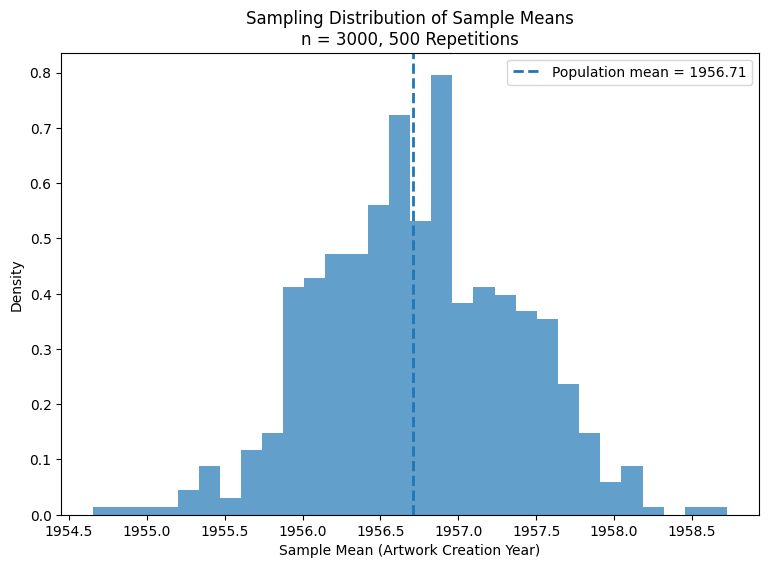

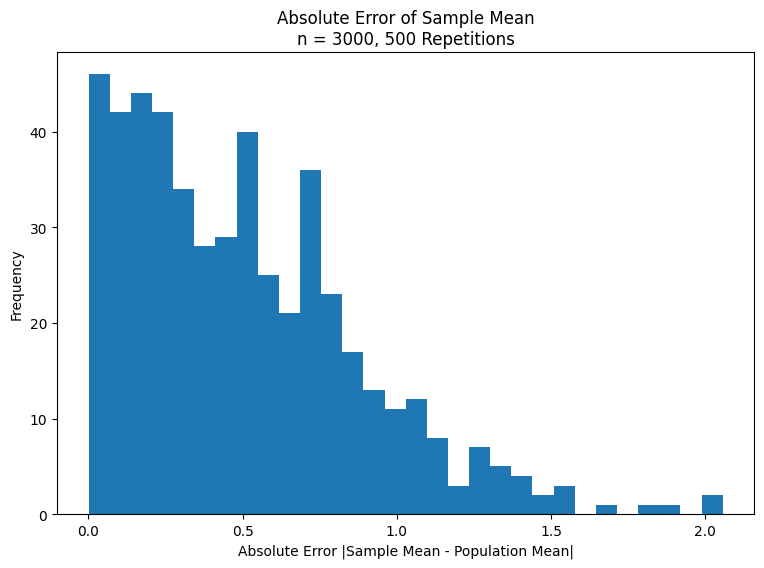

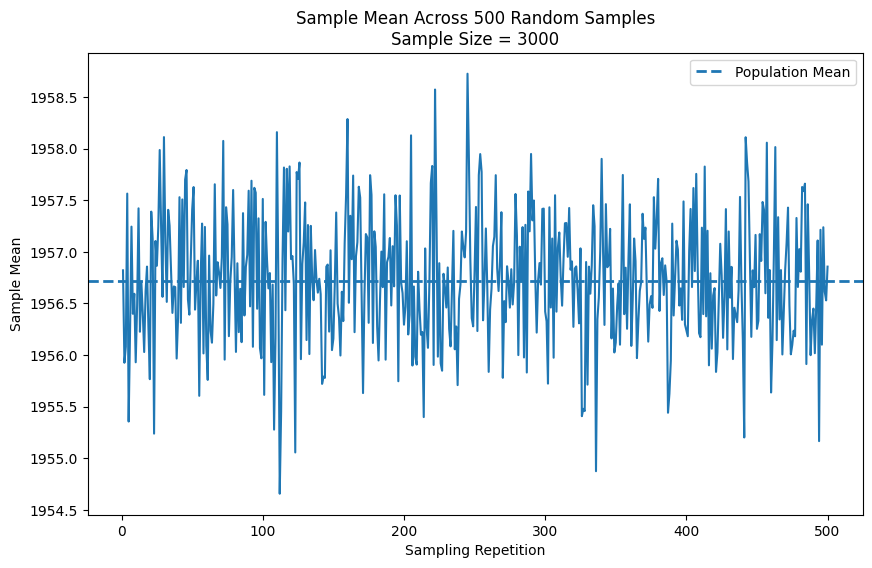

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. Load cleaned data
# ============================================================

df = pd.read_csv("Artworks_cleaned_all.csv")


# ============================================================
# 2. Keep valid midpoint years
#
# Do NOT filter based on the later Bayesian prior.
# ============================================================

years = df["year_mid"].dropna().astype(float)

N = len(years)

print("Number of usable artworks:", N)


# ============================================================
# 3. Population statistics
# ============================================================

population_mean = years.mean()

# ddof=0 because here we are treating the cleaned MoMA dataset
# itself as the population of interest.
population_sd = years.std(ddof=0)

print(f"Population mean: {population_mean:.2f}")
print(f"Population SD:   {population_sd:.2f}")


# ============================================================
# 4. Sampling settings
# ============================================================

sample_size = 3000
n_repetitions = 500

rng = np.random.default_rng(42)


# ============================================================
# 5. Repeated random sampling
# ============================================================

results = []

for i in range(n_repetitions):

    # Random sample WITHOUT replacement within each sample
    sample = rng.choice(
        years.to_numpy(),
        size=sample_size,
        replace=False
    )

    # Mean of this sample
    sample_mean = np.mean(sample)

    # Standard deviation of observations inside this sample
    # ddof=1 = usual sample standard deviation
    sample_sd = np.std(sample, ddof=1)

    # Distance from the true population mean
    absolute_error = abs(sample_mean - population_mean)

    results.append({
        "iteration": i + 1,
        "sample_size": sample_size,
        "sample_mean": sample_mean,
        "sample_sd": sample_sd,
        "absolute_error": absolute_error
    })


results_df = pd.DataFrame(results)


# ============================================================
# 6. Look at first few samples
# ============================================================

print("\nFirst 10 repetitions:")
print(results_df.head(10))


# ============================================================
# 7. Summary statistics
# ============================================================

mean_of_sample_means = results_df["sample_mean"].mean()

# THIS is the SD of the sampling distribution
empirical_se = results_df["sample_mean"].std(ddof=1)

mean_absolute_error = results_df["absolute_error"].mean()

median_absolute_error = results_df["absolute_error"].median()

max_absolute_error = results_df["absolute_error"].max()


print("\n===== Sampling Summary =====")

print(
    f"Population mean:             "
    f"{population_mean:.3f}"
)

print(
    f"Mean of 500 sample means:    "
    f"{mean_of_sample_means:.3f}"
)

print(
    f"SD of sample means:          "
    f"{empirical_se:.3f}"
)

print(
    f"Mean absolute error:         "
    f"{mean_absolute_error:.3f}"
)

print(
    f"Median absolute error:       "
    f"{median_absolute_error:.3f}"
)

print(
    f"Maximum absolute error:      "
    f"{max_absolute_error:.3f}"
)


# ============================================================
# 8. Theoretical Standard Error
#
# Basic CLT formula:
# SE = sigma / sqrt(n)
# ============================================================

theoretical_se_basic = (
    population_sd / np.sqrt(sample_size)
)


# ============================================================
# Because sampling is WITHOUT replacement from a finite
# population, we can also use the finite population correction:
#
# sqrt((N-n)/(N-1))
# ============================================================

finite_population_correction = np.sqrt(
    (N - sample_size) / (N - 1)
)

theoretical_se_fpc = (
    theoretical_se_basic *
    finite_population_correction
)


print("\n===== CLT / SE Comparison =====")

print(
    f"Basic theoretical SE:        "
    f"{theoretical_se_basic:.3f}"
)

print(
    f"SE with finite-pop correction:"
    f" {theoretical_se_fpc:.3f}"
)

print(
    f"Empirical SD of sample means:"
    f" {empirical_se:.3f}"
)


# ============================================================
# 9. Sampling distribution of sample means
# ============================================================

plt.figure(figsize=(9, 6))

plt.hist(
    results_df["sample_mean"],
    bins=30,
    density=True,
    alpha=0.7
)

plt.axvline(
    population_mean,
    linestyle="--",
    linewidth=2,
    label=f"Population mean = {population_mean:.2f}"
)

plt.xlabel("Sample Mean (Artwork Creation Year)")
plt.ylabel("Density")
plt.title(
    "Sampling Distribution of Sample Means\n"
    "n = 3000, 500 Repetitions"
)

plt.legend()

plt.show()


# ============================================================
# 10. Absolute error distribution
# ============================================================

plt.figure(figsize=(9, 6))

plt.hist(
    results_df["absolute_error"],
    bins=30
)

plt.xlabel(
    "Absolute Error |Sample Mean - Population Mean|"
)

plt.ylabel("Frequency")

plt.title(
    "Absolute Error of Sample Mean\n"
    "n = 3000, 500 Repetitions"
)

plt.show()


# ============================================================
# 11. Sample mean across repetitions
#
# This helps visually show how the estimates fluctuate around
# the population mean.
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    results_df["iteration"],
    results_df["sample_mean"]
)

plt.axhline(
    population_mean,
    linestyle="--",
    linewidth=2,
    label="Population Mean"
)

plt.xlabel("Sampling Repetition")
plt.ylabel("Sample Mean")

plt.title(
    "Sample Mean Across 500 Random Samples\n"
    "Sample Size = 3000"
)

plt.legend()

plt.show()


# ============================================================
# 12. Save results if needed
# ============================================================

results_df.to_csv(
    "sampling_results_n3000_500reps.csv",
    index=False
)

In [ ]:
df = pd.read_csv(
    "Artworks.csv",
    low_memory=False
)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (160700, 30)


,Title,Artist,ConstituentID,ArtistBio,Nationality,BeginDate,EndDate,Gender,Date,Medium,...,OnView,Circumference (cm),Depth (cm),Diameter (cm),Height (cm),Length (cm),Weight (kg),Width (cm),Seat Height (cm),Duration (sec.)
0,"Ferdinandsbrücke Project, Vienna, Austria (Ele...",Otto Wagner,6210,"(Austrian, 1841–1918)",(Austrian),(1841),(1918),(male),1896,Ink and cut-and-pasted painted pages on paper,...,NaN,NaN,NaN,NaN,48.6000,NaN,NaN,168.9000,NaN,NaN
1,"City of Music, National Superior Conservatory ...",Christian de Portzamparc,7470,"(French, born 1944)",(French),(1944),(0),(male),1987,Paint and colored pencil on print,...,NaN,NaN,NaN,NaN,40.6401,NaN,NaN,29.8451,NaN,NaN
2,"Villa project, outside Vienna, Austria (Elevat...",Emil Hoppe,7605,"(Austrian, 1876–1957)",(Austrian),(1876),(1957),(male),1903,"Graphite, pen, color pencil, ink, and gouache ...",...,NaN,NaN,NaN,NaN,34.3000,NaN,NaN,31.8000,NaN,NaN
3,"The Manhattan Transcripts Project, New York, N...",Bernard Tschumi,7056,"(French and Swiss, born Switzerland 1944)",(),(1944),(0),(male),1980,Photographic reproduction with colored synthet...,...,NaN,NaN,NaN,NaN,50.8000,NaN,NaN,50.8000,NaN,NaN
4,"Villa project, outside Vienna, Austria (Exteri...",Emil Hoppe,7605,"(Austrian, 1876–1957)",(Austrian),(1876),(1957),(male),1903,"Graphite, color pencil, ink, and gouache on tr...",...,NaN,NaN,NaN,NaN,38.4000,NaN,NaN,19.1000,NaN,NaN


In [ ]:
print(df.columns.tolist())

df.info()

['Title', 'Artist', 'ConstituentID', 'ArtistBio', 'Nationality', 'BeginDate', 'EndDate', 'Gender', 'Date', 'Medium', 'Dimensions', 'CreditLine', 'AccessionNumber', 'Classification', 'Department', 'DateAcquired', 'Cataloged', 'ObjectID', 'URL', 'ImageURL', 'OnView', 'Circumference (cm)', 'Depth (cm)', 'Diameter (cm)', 'Height (cm)', 'Length (cm)', 'Weight (kg)', 'Width (cm)', 'Seat Height (cm)', 'Duration (sec.)']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160700 entries, 0 to 160699
Data columns (total 30 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Title               160652 non-null  object 
 1   Artist              159442 non-null  object 
 2   ConstituentID       159442 non-null  object 
 3   ArtistBio           154016 non-null  object 
 4   Nationality         159442 non-null  object 
 5   BeginDate           159442 non-null  object 
 6   EndDate             159442 non-null  object 
 7   Gender           

In [ ]:
print("Exact duplicate rows:", df.duplicated().sum())

print("Duplicate ObjectIDs:", df["ObjectID"].duplicated().sum())

Exact duplicate rows: 0
Duplicate ObjectIDs: 0


In [ ]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": df.isna().mean() * 100
})

missing_summary = missing_summary.sort_values(
    "Missing_Percent",
    ascending=False
)

missing_summary

,Missing_Count,Missing_Percent
Seat Height (cm),160700,100.000000
Circumference (cm),160690,99.993777
Weight (kg),160398,99.812072
Length (cm),159962,99.540759
OnView,159442,99.217175
Diameter (cm),159300,99.128811
Duration (sec.),158710,98.761668
Depth (cm),141962,88.339764
ImageURL,65122,40.523958
URL,56587,35.212819


In [ ]:
print(df["Cataloged"].value_counts())

print("\nProportions:")
print(df["Cataloged"].value_counts(normalize=True))

Cataloged
Y    104113
N     56587
Name: count, dtype: int64

Proportions:
Cataloged
Y    0.647872
N    0.352128
Name: proportion, dtype: float64


In [ ]:
# Clean text columns 去掉文本字段前后的空格，并把空字符串统一变成 missing value。
text_columns = [
    "Title",
    "Artist",
    "ArtistBio",
    "Nationality",
    "Gender",
    "Date",
    "Medium",
    "Dimensions",
    "CreditLine",
    "AccessionNumber",
    "Classification",
    "Department",
    "Cataloged",
    "URL",
    "ImageURL",
    "OnView"
]

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

    df[col] = df[col].replace(
        ["", " ", "nan", "None", "<NA>"],
        pd.NA
    )

In [ ]:
df["Cataloged_binary"] = df["Cataloged"].map({
    "Y": 1,
    "N": 0
})

df["Cataloged_binary"].value_counts(dropna=False)

,count
Cataloged_binary,
1,104113
0,56587


In [ ]:
df["DateAcquired_clean"] = pd.to_datetime(
    df["DateAcquired"],
    errors="coerce"
)

df["AcquisitionYear"] = (
    df["DateAcquired_clean"]
    .dt.year
)

df[
    ["DateAcquired", "DateAcquired_clean", "AcquisitionYear"]
].head()

,DateAcquired,DateAcquired_clean,AcquisitionYear
0,1996-04-09,1996-04-09,1996.0
1,1995-01-17,1995-01-17,1995.0
2,1997-01-15,1997-01-15,1997.0
3,1995-01-17,1995-01-17,1995.0
4,1997-01-15,1997-01-15,1997.0


In [ ]:
df["AcquisitionDecade"] = (
    df["AcquisitionYear"] // 10 * 10
)

df["AcquisitionDecade"].value_counts().sort_index()

,count
AcquisitionDecade,
1920.0,9
1930.0,1827
1940.0,7650
1950.0,6403
1960.0,44796
1970.0,13611
1980.0,10220
1990.0,11691
2000.0,25182


In [ ]:
df["ArtworkYear"] = (
    df["Date"]
    .str.extract(r"(\d{4})", expand=False)
)

df["ArtworkYear"] = pd.to_numeric(
    df["ArtworkYear"],
    errors="coerce"
)

df[
    ["Date", "ArtworkYear"]
].head(20)





,Date,ArtworkYear
0,1896,1896
1,1987,1987
2,1903,1903
3,1980,1980
4,1903,1903
5,1976-77,1976
6,1976-77,1976
7,1976-77,1976
8,1976-77,1976
9,1976-77,1976


In [ ]:
# remove impossible year
print(
    df["ArtworkYear"].min(),
    df["ArtworkYear"].max()
)

df.loc[
    (df["ArtworkYear"] < 1000) |
    (df["ArtworkYear"] > 2026),
    "ArtworkYear"
] = np.nan

1768 3000


In [ ]:
numeric_columns = [
    "Circumference (cm)",
    "Depth (cm)",
    "Diameter (cm)",
    "Height (cm)",
    "Length (cm)",
    "Weight (kg)",
    "Width (cm)",
    "Seat Height (cm)",
    "Duration (sec.)"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

In [ ]:
metadata_fields = [
    "Title",
    "Artist",
    "Nationality",
    "Date",
    "Medium",
    "Dimensions",
    "CreditLine",
    "Classification",
    "Department",
    "DateAcquired"
]

In [ ]:
df["MetadataFieldsPresent"] = (
    df[metadata_fields]
    .notna()
    .sum(axis=1)
)

df["MetadataCompleteness"] = (
    df["MetadataFieldsPresent"]
    / len(metadata_fields)
)

df[
    [
        "Title",
        "MetadataFieldsPresent",
        "MetadataCompleteness"
    ]
].head()

,Title,MetadataFieldsPresent,MetadataCompleteness
0,"Ferdinandsbrücke Project, Vienna, Austria (Ele...",10,1.0
1,"City of Music, National Superior Conservatory ...",10,1.0
2,"Villa project, outside Vienna, Austria (Elevat...",10,1.0
3,"The Manhattan Transcripts Project, New York, N...",10,1.0
4,"Villa project, outside Vienna, Austria (Exteri...",10,1.0


In [ ]:
# ============================================================
# 16. INSPECT METADATA COMPLETENESS
# ============================================================

print("Metadata completeness summary:")
print(df["MetadataCompleteness"].describe())

print("\nMetadata completeness distribution:")
print(
    df["MetadataCompleteness"]
    .value_counts()
    .sort_index()
)


# ============================================================
# 17. CREATE INDIVIDUAL MISSINGNESS INDICATORS
# ============================================================

# Create a binary missingness variable for each core metadata field:
# 1 = missing
# 0 = present

for col in metadata_fields:
    new_col = "Missing_" + col.replace(" ", "_")
    df[new_col] = df[col].isna().astype(int)


# ============================================================
# 18. CHECK CLEANED CATALOGED OUTCOME
# ============================================================

print("\nCataloged binary distribution:")
print(
    df["Cataloged_binary"]
    .value_counts(dropna=False)
)

print(
    "\nOverall cataloged proportion:",
    df["Cataloged_binary"].mean()
)


# ============================================================
# 19. CHECK DEPARTMENT DISTRIBUTION
# ============================================================

print(
    "\nNumber of departments:",
    df["Department"].nunique()
)

print("\nArtwork count by department:")
print(
    df["Department"]
    .value_counts()
)


# ============================================================
# 20. CREATE DEPARTMENT SUMMARY
# ============================================================

# Calculate:
# N = number of artwork records
# Cataloged_N = number of cataloged artworks
# Cataloged_Rate = proportion cataloged
# Mean_Metadata_Completeness = average completeness score

department_summary = (
    df
    .groupby("Department")
    .agg(
        N=("ObjectID", "count"),
        Cataloged_N=("Cataloged_binary", "sum"),
        Cataloged_Rate=("Cataloged_binary", "mean"),
        Mean_Metadata_Completeness=(
            "MetadataCompleteness",
            "mean"
        )
    )
    .sort_values(
        "N",
        ascending=False
    )
)

print("\nDepartment summary:")
display(department_summary)


# ============================================================
# 21. COMPARE METADATA COMPLETENESS BY CATALOG STATUS
# ============================================================

# Compare metadata completeness between:
# Cataloged = Y
# Cataloged = N

completeness_summary = (
    df
    .groupby("Cataloged")
    ["MetadataCompleteness"]
    .agg([
        "count",
        "mean",
        "median",
        "std"
    ])
)

print("\nMetadata completeness by catalog status:")
display(completeness_summary)


# ============================================================
# 22. CALCULATE MISSINGNESS BY METADATA FIELD
# ============================================================

# Percentage of records missing each core metadata field

metadata_missingness = (
    df[metadata_fields]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

metadata_missingness = metadata_missingness.to_frame(
    name="Missing_Percent"
)

print("\nMissingness by metadata field:")
display(metadata_missingness)


# ============================================================
# 23. CREATE FINAL ANALYSIS DATAFRAME
# ============================================================

# Select variables that are useful for later:
# EDA
# sampling
# MLE
# statistical analysis

analysis_columns = [
    "ObjectID",
    "Title",
    "Artist",
    "Nationality",
    "Gender",
    "Date",
    "ArtworkYear",
    "Medium",
    "Classification",
    "Department",
    "DateAcquired_clean",
    "AcquisitionYear",
    "AcquisitionDecade",
    "Cataloged_binary",
    "MetadataFieldsPresent",
    "MetadataCompleteness"
]

analysis_df = df[
    analysis_columns
].copy()

print("\nPreview of final analysis dataset:")
display(analysis_df.head())


# ============================================================
# 24. FINAL SANITY CHECK
# ============================================================

print(
    "\nFinal analysis dataset shape:",
    analysis_df.shape
)

print("\nData types:")
print(
    analysis_df.dtypes
)

print("\nMissing values in final analysis dataset:")
print(
    analysis_df
    .isna()
    .sum()
    .sort_values(ascending=False)
)


# ============================================================
# 25. SAVE CLEANED DATASETS
# ============================================================

# Main cleaned dataset
analysis_df.to_csv(
    "moma_artworks_clean.csv",
    index=False
)

# Department-level summary
department_summary.to_csv(
    "moma_department_summary.csv"
)

# Metadata missingness summary
metadata_missingness.to_csv(
    "moma_metadata_missingness.csv"
)

print("\nCleaning complete.")
print("Saved files:")
print("- moma_artworks_clean.csv")
print("- moma_department_summary.csv")
print("- moma_metadata_missingness.csv")

Metadata completeness summary:
count    160700.000000
mean          0.982345
std           0.050796
min           0.400000
25%           1.000000
50%           1.000000
75%           1.000000
max           1.000000
Name: MetadataCompleteness, dtype: float64

Metadata completeness distribution:
MetadataCompleteness
0.4        16
0.5       184
0.6       211
0.7      1079
0.8      2468
0.9     18338
1.0    138404
Name: count, dtype: int64

Cataloged binary distribution:
Cataloged_binary
1    104113
0     56587
Name: count, dtype: int64

Overall cataloged proportion: 0.6478718108276291

Number of departments: 8

Artwork count by department:
Department
Drawings & Prints                        82224
Architecture & Design                    34539
Photography                              33815
Painting & Sculpture                      4093
Media and Performance                     3295
Fluxus Collection                         1684
Film                                      1019
Architecture & 

,N,Cataloged_N,Cataloged_Rate,Mean_Metadata_Completeness
Department,,,,
Drawings & Prints,82224,53041,0.645079,0.981831
Architecture & Design,34539,16420,0.475405,0.985005
Photography,33815,27943,0.826349,0.993627
Painting & Sculpture,4093,3975,0.971170,0.998339
Media and Performance,3295,2722,0.826100,0.992686
Fluxus Collection,1684,0,0.000000,0.789430
Film,1019,12,0.011776,0.782924
Architecture & Design - Image Archive,31,0,0.000000,0.900000



Metadata completeness by catalog status:


,count,mean,median,std
Cataloged,,,,
N,56587,0.957066,1.0,0.074831
Y,104113,0.996085,1.0,0.020077



Missingness by metadata field:


,Missing_Percent
Medium,5.424393
Dimensions,5.182327
DateAcquired,3.398880
Date,1.254512
CreditLine,0.798382
Artist,0.782825
Nationality,0.782825
Title,0.029869
Classification,0.000622
Department,0.000000



Preview of final analysis dataset:


,ObjectID,Title,Artist,Nationality,Gender,Date,ArtworkYear,Medium,Classification,Department,DateAcquired_clean,AcquisitionYear,AcquisitionDecade,Cataloged_binary,MetadataFieldsPresent,MetadataCompleteness
0,2,"Ferdinandsbrücke Project, Vienna, Austria (Ele...",Otto Wagner,(Austrian),(male),1896,1896,Ink and cut-and-pasted painted pages on paper,Architecture,Architecture & Design,1996-04-09,1996.0,1990.0,1,10,1.0
1,3,"City of Music, National Superior Conservatory ...",Christian de Portzamparc,(French),(male),1987,1987,Paint and colored pencil on print,Architecture,Architecture & Design,1995-01-17,1995.0,1990.0,1,10,1.0
2,4,"Villa project, outside Vienna, Austria (Elevat...",Emil Hoppe,(Austrian),(male),1903,1903,"Graphite, pen, color pencil, ink, and gouache ...",Architecture,Architecture & Design,1997-01-15,1997.0,1990.0,1,10,1.0
3,5,"The Manhattan Transcripts Project, New York, N...",Bernard Tschumi,(),(male),1980,1980,Photographic reproduction with colored synthet...,Architecture,Architecture & Design,1995-01-17,1995.0,1990.0,1,10,1.0
4,6,"Villa project, outside Vienna, Austria (Exteri...",Emil Hoppe,(Austrian),(male),1903,1903,"Graphite, color pencil, ink, and gouache on tr...",Architecture,Architecture & Design,1997-01-15,1997.0,1990.0,1,10,1.0



Final analysis dataset shape: (160700, 16)

Data types:
ObjectID                          int64
Title                    string[python]
Artist                   string[python]
Nationality              string[python]
Gender                   string[python]
Date                     string[python]
ArtworkYear                       Int64
Medium                   string[python]
Classification           string[python]
Department               string[python]
DateAcquired_clean       datetime64[ns]
AcquisitionYear                 float64
AcquisitionDecade               float64
Cataloged_binary                  int64
MetadataFieldsPresent             int64
MetadataCompleteness            float64
dtype: object

Missing values in final analysis dataset:
Medium                   8717
AcquisitionDecade        5462
DateAcquired_clean       5462
AcquisitionYear          5462
ArtworkYear              4427
Date                     2016
Artist                   1258
Nationality              1258
Gender

In [ ]:
# Shiqi Liu's data cleaning
# Import libraries
import pandas as pd
import numpy as np
import re


df = pd.read_csv("/Artworks.csv")

print("Original dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()


# ============================================
# 2. Rename the original date column
# ============================================

df = df.rename(columns={"#SPILL!": "DateOriginal"})

print("\nFirst few original date values:")
print(df["DateOriginal"].head(10))


# ============================================
# 3. Define the date-cleaning function
# ============================================

def clean_date(value):

    # Missing value
    if pd.isna(value):
        return np.nan

    text = str(value).strip()
    lower = text.lower()

    # ----------------------------------------
    # Rule 1: Remove missing or unknown dates
    # ----------------------------------------
    if lower in ["", "unknown", "n.d.", "n.d", "nd"]:
        return np.nan

    # ----------------------------------------
    # Rule 2: Remove "Before" or "After"
    # ----------------------------------------
    if "before" in lower or "after" in lower:
        return np.nan

    # ----------------------------------------
    # Rule 3: Remove B.C. dates
    # ----------------------------------------
    if (
        "b.c." in lower
        or "b.c" in lower
        or re.search(r"\bbc\b", lower)
    ):
        return np.nan

    # ----------------------------------------
    # Rule 4: Published year
    # Example:
    # "Published 1949 (...)" -> 1949
    # ----------------------------------------
    published = re.search(
        r"published\s+(\d{4})",
        lower
    )

    if published:
        return float(published.group(1))

    # ----------------------------------------
    # Rule 5: Circa year
    # Examples:
    # "c. 1920" -> 1920
    # "circa 1920" -> 1920
    # ----------------------------------------
    circa = re.search(
        r"(?:circa|c\.)\s*(\d{4})",
        lower
    )

    if circa:
        return float(circa.group(1))

    # ----------------------------------------
    # Rule 6: Early decade
    # Example:
    # "early 1920s" -> 1922
    # ----------------------------------------
    early_decade = re.search(
        r"early\s+(\d{4})s",
        lower
    )

    if early_decade:
        start_year = int(early_decade.group(1))
        return float(start_year + 2)

    # ----------------------------------------
    # Rule 7: Mid decade
    # Example:
    # "mid 1920s" -> 1925
    # ----------------------------------------
    mid_decade = re.search(
        r"mid[-\s]*(\d{4})s",
        lower
    )

    if mid_decade:
        start_year = int(mid_decade.group(1))
        return float(start_year + 5)

    # ----------------------------------------
    # Rule 8: Late decade
    # Example:
    # "late 1920s" -> 1927
    # ----------------------------------------
    late_decade = re.search(
        r"late\s+(\d{4})s",
        lower
    )

    if late_decade:
        start_year = int(late_decade.group(1))
        return float(start_year + 7)

    # ----------------------------------------
    # Rule 9: Full decade
    # Example:
    # "1920s" -> midpoint = 1924.5
    # ----------------------------------------
    decade = re.fullmatch(
        r"(\d{4})s",
        lower
    )

    if decade:
        start_year = int(decade.group(1))
        return start_year + 4.5

    # ----------------------------------------
    # Rule 10: Full year range
    # Example:
    # "1955-1958" -> 1956.5
    # ----------------------------------------
    full_range = re.fullmatch(
        r"\s*(\d{4})\s*[-–—]\s*(\d{4})\s*",
        text
    )

    if full_range:
        start_year = int(full_range.group(1))
        end_year = int(full_range.group(2))

        if end_year >= start_year:
            return (start_year + end_year) / 2

    # ----------------------------------------
    # Rule 11: Short year range
    # Example:
    # "1955-58" -> [1955, 1958]
    # midpoint = 1956.5
    # ----------------------------------------
    short_range = re.fullmatch(
        r"\s*(\d{4})\s*[-–—]\s*(\d{2})\s*",
        text
    )

    if short_range:
        start_year = int(short_range.group(1))
        short_end = int(short_range.group(2))

        century = (start_year // 100) * 100
        end_year = century + short_end

        # Handle ranges crossing into the next century
        if end_year < start_year:
            end_year += 100

        return (start_year + end_year) / 2

    # ----------------------------------------
    # Rule 12: Exact year
    # Example:
    # "1965" -> 1965
    # ----------------------------------------
    exact_year = re.fullmatch(
        r"\d{4}",
        text
    )

    if exact_year:
        return float(text)

    # ----------------------------------------
    # Rule 13: Full date with one clear year
    # Example:
    # "March 12, 1854" -> 1854
    # ----------------------------------------
    year_matches = re.findall(
        r"\b(1[0-9]{3}|20[0-9]{2})\b",
        text
    )

    if len(year_matches) == 1:
        return float(year_matches[0])

    # ----------------------------------------
    # Anything that cannot be interpreted
    # reliably becomes missing
    # ----------------------------------------
    return np.nan


# ============================================
# 4. Apply the cleaning function
# ============================================

df["DateCleaned"] = df["DateOriginal"].apply(clean_date)

print("\nExample cleaned dates:")
print(
    df[
        ["DateOriginal", "DateCleaned"]
    ].head(20)
)


# ============================================
# 5. Keep only years from 1800 to 2026
# ============================================

df_clean = df[
    df["DateCleaned"].between(
        1800,
        2026,
        inclusive="both"
    )
].copy()


# ============================================
# 6. Check the cleaning results
# ============================================

print("\nCleaning summary")
print("----------------------------")

print(
    "Original number of rows:",
    len(df)
)

print(
    "Cleaned number of rows:",
    len(df_clean)
)

print(
    "Removed rows:",
    len(df) - len(df_clean)
)

print(
    "Percentage retained:",
    round(
        len(df_clean) / len(df) * 100,
        2
    ),
    "%"
)


# ============================================
# 7. Check descriptive statistics
# ============================================

print("\nDateCleaned summary statistics:")
print(
    df_clean[
        "DateCleaned"
    ].describe()
)

print(
    "\nMinimum year:",
    df_clean["DateCleaned"].min()
)

print(
    "Maximum year:",
    df_clean["DateCleaned"].max()
)


# ============================================
# 8. Randomly inspect cleaned values
# ============================================

print("\nRandom sample of cleaned dates:")

print(
    df_clean[
        ["DateOriginal", "DateCleaned"]
    ].sample(
        20,
        random_state=42
    )
)


# ============================================
# 9. Check values that were removed
# ============================================

removed_dates = df[
    df["DateCleaned"].isna()
][
    ["DateOriginal"]
]

print("\nExamples of dates removed during cleaning:")

print(
    removed_dates.head(30)
)


# ============================================
# 10. Calculate population statistics
# ============================================

population_size = len(df_clean)

population_mean = (
    df_clean["DateCleaned"].mean()
)

population_median = (
    df_clean["DateCleaned"].median()
)

# ddof=0 because the cleaned dataset
# is treated as the population
population_std = (
    df_clean["DateCleaned"].std(
        ddof=0
    )
)


print("\nPopulation statistics")
print("----------------------------")

print(
    "Population size:",
    population_size
)

print(
    "Population mean year:",
    round(population_mean, 2)
)

print(
    "Population median year:",
    round(population_median, 2)
)

print(
    "Population standard deviation:",
    round(population_std, 2)
)


# ============================================
# 11. Save the cleaned dataset
# ============================================

output_file = "Artworks_cleaned_dates.csv"

df_clean.to_csv(
    output_file,
    index=False
)

print(
    "\nCleaned dataset saved as:",
    output_file
)

Original dataset shape: (160700, 30)

Column names:
['Title', 'Artist', 'ConstituentID', 'ArtistBio', 'Nationality', 'BeginDate', 'EndDate', 'Gender', '#SPILL!', 'Medium', 'Dimensions', 'CreditLine', 'AccessionNumber', 'Classification', 'Department', 'DateAcquired', 'Cataloged', 'ObjectID', 'URL', 'ImageURL', 'OnView', 'Circumference (cm)', 'Depth (cm)', 'Diameter (cm)', 'Height (cm)', 'Length (cm)', 'Weight (kg)', 'Width (cm)', 'Seat Height (cm)', 'Duration (sec.)']

First few original date values:
0       1896
1       1987
2       1903
3       1980
4       1903
5    1976-77
6    1976-77
7    1976-77
8    1976-77
9    1976-77
Name: DateOriginal, dtype: object

Example cleaned dates:
   DateOriginal  DateCleaned
0          1896       1896.0
1          1987       1987.0
2          1903       1903.0
3          1980       1980.0
4          1903       1903.0
5       1976-77       1976.5
6       1976-77       1976.5
7       1976-77       1976.5
8       1976-77       1976.5
9       1976-77  

In [ ]:
# Shiqi Liu: Sample experiment

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Load the SAME cleaned dataset used for n=3000
# ============================================================

years_1000 = years.copy()

years_1000 = df_1000["year_mid"].dropna().astype(float)
values_1000 = years_1000.to_numpy()

N = len(years_1000)

# ============================================================
# 2. Population statistics
# ============================================================

population_mean_1000 = years_1000.mean()
population_sd_1000 = years_1000.std(ddof=0)

print("Number of usable artworks:", N)
print(f"Population mean: {population_mean_1000:.3f}")
print(f"Population SD: {population_sd_1000:.3f}")

# ============================================================
# 3. Sampling settings
# ============================================================

sample_size = 1000
n_repetitions = 500

rng = np.random.default_rng(42)

# ============================================================
# 4. Repeated random sampling
# ============================================================

results = []

for i in range(n_repetitions):

    # Randomly select 1000 artworks without replacement
    sample = rng.choice(
        values_1000,
        size=sample_size,
        replace=False
    )

    sample_mean = np.mean(sample)
    sample_sd = np.std(sample, ddof=1)

    absolute_error = abs(
        sample_mean - population_mean_1000
    )

    results.append({
        "iteration": i + 1,
        "sample_size": sample_size,
        "sample_mean": sample_mean,
        "sample_sd": sample_sd,
        "absolute_error": absolute_error
    })

results_1000_df = pd.DataFrame(results)

print("\nFirst 10 repetitions:")
print(results_1000_df.head(10))

# ============================================================
# 5. Summary statistics
# ============================================================

mean_of_sample_means = (
    results_1000_df["sample_mean"].mean()
)

empirical_se = (
    results_1000_df["sample_mean"].std(ddof=1)
)

mean_absolute_error = (
    results_1000_df["absolute_error"].mean()
)

median_absolute_error = (
    results_1000_df["absolute_error"].median()
)

max_absolute_error = (
    results_1000_df["absolute_error"].max()
)

print("\n===== Sampling Summary: n=1000 =====")

print(f"Population mean:           {population_mean_1000:.3f}")
print(f"Mean of 500 sample means:  {mean_of_sample_means:.3f}")
print(f"SD of sample means:        {empirical_se:.3f}")
print(f"Mean absolute error:       {mean_absolute_error:.3f}")
print(f"Median absolute error:     {median_absolute_error:.3f}")
print(f"Maximum absolute error:    {max_absolute_error:.3f}")

# ============================================================
# 6. Theoretical Standard Error (CLT)
# ============================================================

theoretical_se_basic = (
    population_sd_1000 / np.sqrt(sample_size)
)

# Finite population correction
fpc = np.sqrt((N - sample_size) / (N - 1))

theoretical_se_fpc = theoretical_se_basic * fpc

print("\n===== CLT / SE Comparison =====")

print(f"Basic theoretical SE:      {theoretical_se_basic:.3f}")
print(f"SE with FPC:               {theoretical_se_fpc:.3f}")
print(f"Empirical SD of means:     {empirical_se:.3f}")

# ============================================================
# 7. Plot 1: Sampling distribution
# ============================================================

plt.figure(figsize=(9, 6))

plt.hist(
    results_1000_df["sample_mean"],
    bins=30,
    density=True,
    alpha=0.7
)

plt.axvline(
    population_mean_1000,
    linestyle="--",
    linewidth=2,
    label=f"Population mean = {population_mean_1000:.2f}"
)

plt.xlabel("Sample Mean (Artwork Creation Year)")
plt.ylabel("Density")
plt.title("Sampling Distribution of Sample Means\n"
          "n = 1000, 500 Repetitions")
plt.legend()
plt.show()

# ============================================================
# 8. Plot 2: Absolute error distribution
# ============================================================

plt.figure(figsize=(9, 6))

plt.hist(
    results_1000_df["absolute_error"],
    bins=30
)

plt.xlabel("Absolute Error")
plt.ylabel("Frequency")
plt.title("Absolute Error of Sample Mean\n"
          "n = 1000, 500 Repetitions")
plt.show()

# ============================================================
# 9. Plot 3: Sample means across repetitions
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    results_1000_df["iteration"],
    results_1000_df["sample_mean"]
)

plt.axhline(
    population_mean_1000,
    linestyle="--",
    linewidth=2,
    label="Population Mean"
)

plt.xlabel("Sampling Repetition")
plt.ylabel("Sample Mean")
plt.title("Sample Mean Across 500 Random Samples\n"
          "Sample Size = 1000")
plt.legend()
plt.show()

# ============================================================
# 10. Save results
# ============================================================

results_1000_df.to_csv(
    "sampling_results_n1000_500reps.csv",
    index=False
)

print("\nResults saved successfully.")


NameError: name 'years' is not defined